# Módulo 25 · Práctica: diseño de experimentos, modelos sustitutos y optimización bayesiana

En una planta no se puede probar todo: cada experimento cuesta material, horas de máquina o semanas de espera. Este cuaderno recorre, con simuladores sintéticos pero realistas, los **casos de estudio de los apuntes del módulo 25**: el ajuste de una inyectora de plástico, la receta de un hormigón con menos CO₂ y el ajuste de hiperparámetros de un modelo de aprendizaje automático.

| Parte | Qué haces | Apuntes |
| --- | --- | --- |
| 0 | Preparación y utilidades | |
| 1 | El problema: coste por pieza buena, ruido y la maldición del ganador | Tema 1 |
| 2 | Diseño de experimentos: factorial $2^3$, ANOVA, hipercubo latino y superficie de respuesta | Tema 2 |
| 3 | Modelos sustitutos: polinomio, proceso gaussiano desde cero, *ensemble* de redes y PINN | Tema 3 |
| 4 | Optimización bayesiana: mejora esperada, restricciones, lotes y frente de Pareto | Tema 4 |
| 5 | Casos de estudio: la inyectora completa y el hormigón bajo en CO₂ | Tema 5 |
| 6 | Ajuste de hiperparámetros: búsqueda aleatoria, TPE, Hyperband, validación del sustituto y parada | Tema 6 |
| 7 | Retos | |

**Cómo trabajar.** Ejecuta las celdas en orden. Las celdas `# TU CÓDIGO` son ejercicios: cada una pide una función. La celda `# Comprobación` de detrás la prueba con `assert`. Si todavía no has resuelto el ejercicio (la función lanza `NotImplementedError`), la comprobación lo avisa y usa la solución de referencia para que el resto del cuaderno siga funcionando; así puedes avanzar y volver después. Las soluciones están al final.

Todos los datos se generan aquí mismo con semillas fijas. Dependencias: `numpy`, `scipy`, `matplotlib`, `scikit-learn` y `torch` (solo en la PINN); `optuna` es opcional (Parte 6) y, si falta, se sustituye por búsqueda aleatoria. Tiempo total en CPU: en torno a un minuto y medio (menos de 5 minutos en un portátil modesto).

## Parte 0 · Preparación

In [1]:
# Dependencias opcionales (descomenta si no las tienes):
# !pip install optuna
import os
for _v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ.setdefault(_v, "1")    # un hilo por biblioteca: evita que OpenMP y OpenBLAS compitan por la CPU
import time, itertools, math, warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import expit
from scipy.stats import qmc, norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, WhiteKernel, ConstantKernel as Ck
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message=".*lbfgs.*")
warnings.filterwarnings("ignore", message="IProgress not found")
np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (6.4, 3.6)
T0_CUADERNO = time.time()
print("numpy", np.__version__)

numpy 2.5.3


La celda siguiente está **plegada**: contiene las soluciones de referencia que se usan solo si un ejercicio está sin hacer. No la abras hasta haberlo intentado.

In [2]:
# Soluciones de referencia (se usan solo si el ejercicio está pendiente)
_REF = {}
def _coste_pieza(t_ciclo, d, c_maq=45.0, c_mat=0.40):
    return (c_maq * np.asarray(t_ciclo) / 3600 + c_mat) / (1 - np.asarray(d))
def _sesgo_ganador(n, sigma, m, rng):
    return sigma * rng.standard_normal((m, n)).max(axis=1).mean()
def _factorial_2k(k):
    return np.array(list(itertools.product([-1, 1], repeat=k)))[:, ::-1].astype(float)
def _tabla_efectos(M, Y):
    Y = np.atleast_2d(Y); N, n = Y.shape
    ybar = Y.mean(axis=1)
    ef = M.T @ ybar / (N / 2)
    return ef, n * N * ef**2 / 4
def _es_hipercubo_latino(U):
    n = U.shape[0]
    return all(np.array_equal(np.sort(np.floor(U[:, j] * n)), np.arange(n)) for j in range(U.shape[1]))
def _punto_estacionario(b, B):
    return -0.5 * np.linalg.solve(B, b)
def _k_se(A, B, ell, sf):
    d2 = ((A[:, None, :] - B[None, :, :])**2).sum(-1)
    return sf**2 * np.exp(-0.5 * d2 / ell**2)
def _gp_posterior(Xtr, ytr, Xte, ell, sf, sn):
    K = _k_se(Xtr, Xtr, ell, sf) + (sn**2 + 1e-10) * np.eye(len(Xtr))
    L = np.linalg.cholesky(K)
    alfa = np.linalg.solve(L.T, np.linalg.solve(L, ytr))
    Ks = _k_se(Xtr, Xte, ell, sf)
    mu = Ks.T @ alfa
    v = np.linalg.solve(L, Ks)
    var = sf**2 - (v**2).sum(0)
    return mu, np.maximum(var, 0)
def _log_verosimilitud_marginal(Xtr, ytr, ell, sf, sn):
    n = len(ytr)
    K = _k_se(Xtr, Xtr, ell, sf) + (sn**2 + 1e-10) * np.eye(n)
    L = np.linalg.cholesky(K)
    alfa = np.linalg.solve(L.T, np.linalg.solve(L, ytr))
    return -0.5 * ytr @ alfa - np.log(np.diag(L)).sum() - 0.5 * n * np.log(2 * np.pi)
def _mezcla_ensemble(mus, sigmas):
    mus, sigmas = np.asarray(mus), np.asarray(sigmas)
    mu = mus.mean(0)
    return mu, np.sqrt((sigmas**2 + mus**2).mean(0) - mu**2)
def _mejora_esperada(mu, sigma, f_mejor):
    mu, sigma = np.asarray(mu, float), np.asarray(sigma, float)
    s = np.maximum(sigma, 1e-12)
    z = (f_mejor - mu) / s
    ei = (f_mejor - mu) * norm.cdf(z) + s * norm.pdf(z)
    return np.where(sigma > 1e-12, ei, np.maximum(f_mejor - mu, 0))
def _ei_restringida(mu_f, s_f, f_mejor, mu_c, s_c, limite):
    return _mejora_esperada(mu_f, s_f, f_mejor) * norm.cdf((limite - np.asarray(mu_c)) / np.maximum(s_c, 1e-12))
def _no_dominados(F):
    F = np.asarray(F)
    return np.array([not np.any(np.all(F <= f, 1) & np.any(F < f, 1)) for f in F])
def _hipervolumen_2d(F, ref):
    F = np.asarray(F); F = F[_no_dominados(F) & np.all(F < ref, 1)]
    F = F[np.argsort(F[:, 0])]
    hv, y_prev = 0.0, ref[1]
    for f1, f2 in F:
        hv += (ref[0] - f1) * (y_prev - f2); y_prev = f2
    return hv
def _ensayos_busqueda_aleatoria(q, p):
    return int(math.ceil(math.log(1 - p) / math.log(1 - q)))
def _brackets_hyperband(R, eta):
    s_max = int(math.floor(math.log(R) / math.log(eta) + 1e-9)); B = (s_max + 1) * R
    out = []
    for s in range(s_max, -1, -1):
        n = int(math.ceil(B / R * eta**s / (s + 1))); r = R * eta**(-s)
        out.append([(int(math.floor(n * eta**(-i))), r * eta**i) for i in range(s + 1)])
    return out
def _loo_gp(K, y):
    Ki = np.linalg.inv(K); d = np.diag(Ki)
    return y - (Ki @ y) / d, 1 / d
for _nombre in ["coste_pieza", "sesgo_ganador", "factorial_2k", "tabla_efectos", "es_hipercubo_latino",
                "punto_estacionario", "gp_posterior", "log_verosimilitud_marginal", "mezcla_ensemble",
                "mejora_esperada", "ei_restringida", "no_dominados", "hipervolumen_2d",
                "ensayos_busqueda_aleatoria", "brackets_hyperband", "loo_gp"]:
    _REF[_nombre] = globals()["_" + _nombre]

In [3]:
def usar_si_falta(func, nombre, *args):
    "Devuelve func si el ejercicio está hecho; si lanza NotImplementedError, avisa y devuelve la referencia."
    try:
        func(*args)
        return func
    except NotImplementedError:
        print(f"[pendiente] Ejercicio «{nombre}» sin resolver: se usa la solución de referencia para continuar.")
        return _REF[nombre]

def ok(msg):
    print("Correcto:", msg)

## Parte 1 · El problema: una inyectora de plástico (tema 1)

Una inyectora fabrica una carcasa de polipropileno. Tres parámetros del proceso:

| Variable | Símbolo | Rango |
| --- | --- | --- |
| temperatura de fusión | $T$ | 200–260 °C |
| presión de mantenimiento | $P$ | 30–90 MPa |
| tiempo de enfriamiento | $t_e$ | 8–30 s |

El simulador de la celda siguiente hace el papel de la planta. Sus fórmulas son **sintéticas** (inventadas para el curso, con órdenes de magnitud plausibles): rechupes si falta presión o enfriamiento, rebabas si sobra presión y temperatura, piezas incompletas si el material está frío. En la vida real no se conocen: solo se observan lotes de piezas. El tiempo de ciclo es $t_c = 8 + t_e + 0{,}05\,(T-200)$ s y el coste por pieza **buena** es

$$C(x)=\frac{c_{\text{máq}}\,t_c(x)/3600 + c_{\text{mat}}}{1-d(x)},\qquad c_{\text{máq}}=45\ \text{€/h},\ c_{\text{mat}}=0{,}40\ \text{€},$$

con $d(x)$ la fracción de piezas defectuosas. Restricción de calidad: alabeo $w(x)\le 0{,}45$ mm.

In [4]:
LIM = np.array([[200., 260.], [30., 90.], [8., 30.]])   # T (°C), P (MPa), t_e (s)
NOMBRES = ["T (°C)", "P (MPa)", "t_e (s)"]
W_MAX = 0.45                                              # alabeo máximo (mm)

def codifica(x):
    "Variables físicas -> codificadas en [-1, 1]."
    x = np.atleast_2d(np.asarray(x, float))
    return (x - LIM.mean(1)) / ((LIM[:, 1] - LIM[:, 0]) / 2)

def a_fisicas(z):
    "Variables en [0, 1] -> físicas."
    return LIM[:, 0] + np.atleast_2d(z) * (LIM[:, 1] - LIM[:, 0])

def tasa_defectos(x):
    uT, uP, ut = codifica(x).T
    rechupe    = expit(-4.4 + 1.0*uT - 1.6*uP - 1.6*ut)
    rebaba     = expit(-4.6 + 2.6*uP + 1.4*uT + 0.6*uP*uT)
    incompleta = expit(-4.6 - 3.0*uT - 1.0*uP)
    return 1 - (1 - rechupe) * (1 - rebaba) * (1 - incompleta)

def alabeo(x):
    uT, uP, ut = codifica(x).T
    return 0.48 - 0.18*ut + 0.08*uT + 0.03*uT*ut + 0.05*ut**2 + 0.04*uP**2

def t_ciclo(x):
    x = np.atleast_2d(np.asarray(x, float))
    return 8.0 + x[:, 2] + 0.05 * (x[:, 0] - 200)

def coste_real(x):
    return (45.0 * t_ciclo(x) / 3600 + 0.40) / (1 - tasa_defectos(x))

def experimento(x, rng, n_lote=200, sd_pieza=0.04, n_med=20):
    "Un lote de 200 piezas: coste observado, fracción defectuosa observada y alabeo medio de 20 piezas."
    x = np.atleast_2d(np.asarray(x, float))
    d_obs = rng.binomial(n_lote, tasa_defectos(x)) / n_lote
    w_obs = alabeo(x) + rng.normal(0, sd_pieza / np.sqrt(n_med), len(x))
    return (45.0 * t_ciclo(x) / 3600 + 0.40) / (1 - d_obs), d_obs, w_obs

# Óptimo verdadero (solo lo conocemos porque el simulador es nuestro): rejilla fina
_g = np.array(list(itertools.product(np.linspace(200, 260, 121), np.linspace(30, 90, 121), np.linspace(8, 30, 177))))
_C, _w = coste_real(_g), alabeo(_g)
_j = np.argmin(np.where(_w <= W_MAX, _C, np.inf))
X_OPT, C_OPT = _g[_j], _C[_j]
print("Óptimo con restricción: T = %.1f °C, P = %.1f MPa, t_e = %.2f s" % tuple(X_OPT))
print("  coste = %.4f €/pieza, defectos = %.2f %%, alabeo = %.3f mm, ciclo = %.2f s"
      % (C_OPT, 100 * tasa_defectos(X_OPT)[0], alabeo(X_OPT)[0], t_ciclo(X_OPT)[0]))
print("Fracción del espacio que cumple el alabeo: %.1f %%" % (100 * (_w <= W_MAX).mean()))
del _g, _C, _w

Óptimo con restricción: T = 213.5 °C, P = 70.5 MPa, t_e = 18.50 s
  coste = 0.7782 €/pieza, defectos = 4.95 %, alabeo = 0.450 mm, ciclo = 27.18 s
Fracción del espacio que cumple el alabeo: 33.1 %


**Ejercicio 1.** Escribe `coste_pieza(t_ciclo, d, c_maq=45.0, c_mat=0.40)` con la fórmula del coste por pieza buena (debe funcionar con arrays). Después úsala para comparar la receta actual del operario, $x_0=(240, 50, 26)$, con el óptimo.

In [5]:
def coste_pieza(t_ciclo, d, c_maq=45.0, c_mat=0.40):
    # TU CÓDIGO
    raise NotImplementedError

In [6]:
# Comprobación
coste_pieza = usar_si_falta(coste_pieza, "coste_pieza", 30.0, 0.05)
assert abs(coste_pieza(36.0, 0.0) - 0.85) < 1e-12, "Sin defectos: 45·36/3600 + 0,40 = 0,85 €"
assert abs(coste_pieza(28.5, 0.05) - (45*28.5/3600 + 0.4) / 0.95) < 1e-12
x0 = np.array([[240., 50., 26.]])
c0 = coste_pieza(t_ciclo(x0), tasa_defectos(x0))[0]
assert abs(c0 - coste_real(x0)[0]) < 1e-12
ok(f"receta actual {c0:.4f} €/pieza (defectos {100*tasa_defectos(x0)[0]:.2f} %, alabeo {alabeo(x0)[0]:.3f} mm, ciclo {t_ciclo(x0)[0]:.1f} s)")
print(f"Ahorro posible: {100*(1 - C_OPT/c0):.1f} % por pieza; con 10^6 piezas/año, {1e6*(c0 - C_OPT):,.0f} €/año".replace(",", "."))

[pendiente] Ejercicio «coste_pieza» sin resolver: se usa la solución de referencia para continuar.
Correcto: receta actual 0.8688 €/pieza (defectos 2.17 %, alabeo 0.423 mm, ciclo 36.0 s)
Ahorro posible: 10.4 % por pieza; con 10^6 piezas/año. 90.602 €/año


**Ruido binomial.** Con lotes de 200 piezas, la fracción defectuosa observada tiene desviación típica $\sqrt{d(1-d)/200}$. Repetimos 2000 veces el experimento en el óptimo para verlo.

In [7]:
rng = np.random.default_rng(0)
c_obs, d_obs, w_obs = experimento(np.repeat(X_OPT[None], 2000, 0), rng)
d_v = tasa_defectos(X_OPT)[0]
print(f"d verdadero = {d_v:.4f}; desv. típica teórica = {np.sqrt(d_v*(1-d_v)/200):.4f}; observada = {d_obs.std():.4f}")
print(f"coste observado: media {c_obs.mean():.4f}, desv. típica {c_obs.std():.4f} €/pieza")
print(f"fracción de lotes en el óptimo que *parecen* violar el alabeo: {np.mean(w_obs > W_MAX):.3f}")

d verdadero = 0.0495; desv. típica teórica = 0.0153; observada = 0.0155
coste observado: media 0.7784, desv. típica 0.0127 €/pieza
fracción de lotes en el óptimo que *parecen* violar el alabeo: 0.488


**Ejercicio 2 · La maldición del ganador.** Si se ensayan $n$ ajustes **igual de buenos** con ruido $\mathcal N(0,\sigma^2)$, el mejor valor observado es optimista en $\sigma\,\mathbb E[\max_i Z_i]$ (proposición 1.6 de los apuntes). Escribe `sesgo_ganador(n, sigma, m, rng)` que estime ese sesgo por Monte Carlo con `m` repeticiones.

In [8]:
def sesgo_ganador(n, sigma, m, rng):
    # TU CÓDIGO
    raise NotImplementedError

In [9]:
# Comprobación
sesgo_ganador = usar_si_falta(sesgo_ganador, "sesgo_ganador", 2, 1.0, 10, np.random.default_rng(0))
s2 = sesgo_ganador(2, 1.0, 200_000, np.random.default_rng(1))
s10 = sesgo_ganador(10, 1.0, 200_000, np.random.default_rng(1))
assert abs(s2 - 1/np.sqrt(np.pi)) < 0.01, "Para n = 2 el valor exacto es 1/sqrt(pi) = 0,5642"
assert abs(s10 - 1.5388) < 0.01, "Para n = 10 el valor exacto es 1,5388"
ok(f"E[max] con n = 2: {s2:.4f} (exacto 0,5642); con n = 10: {s10:.4f} (exacto 1,5388)")
s_c = c_obs.std()
print(f"Con el ruido del coste (σ ≈ {s_c:.4f} €), el mejor de 10 lotes iguales parece {s10*s_c:.4f} € más barato de lo que es.")

[pendiente] Ejercicio «sesgo_ganador» sin resolver: se usa la solución de referencia para continuar.
Correcto: E[max] con n = 2: 0.5609 (exacto 0,5642); con n = 10: 1.5378 (exacto 1,5388)
Con el ruido del coste (σ ≈ 0.0127 €), el mejor de 10 lotes iguales parece 0.0196 € más barato de lo que es.


## Parte 2 · Diseño de experimentos (tema 2)

### 2.1 Factorial $2^3$ con dos réplicas
Factores $A=T\in\{210, 250\}$ °C, $B=P\in\{50, 80\}$ MPa, $C=t_e\in\{14, 26\}$ s; respuesta: alabeo (mm), media de 5 piezas.

**Ejercicio 3.** Escribe `factorial_2k(k)` que devuelva la matriz $2^k\times k$ de niveles codificados $\pm1$ en **orden estándar** (la primera columna alterna más deprisa: $-,+,-,+,\dots$).

In [10]:
def factorial_2k(k):
    # TU CÓDIGO
    raise NotImplementedError

In [11]:
# Comprobación
factorial_2k = usar_si_falta(factorial_2k, "factorial_2k", 2)
U = factorial_2k(3)
assert U.shape == (8, 3)
assert np.array_equal(U[:, 0], [-1, 1, -1, 1, -1, 1, -1, 1]) and np.array_equal(U[:, 2], [-1]*4 + [1]*4)
assert np.allclose(U.T @ U, 8 * np.eye(3)), "Las columnas de un 2^k son ortogonales"
ok("diseño 2^3 en orden estándar\n" + str(U.astype(int)))

[pendiente] Ejercicio «factorial_2k» sin resolver: se usa la solución de referencia para continuar.
Correcto: diseño 2^3 en orden estándar
[[-1 -1 -1]
 [ 1 -1 -1]
 [-1  1 -1]
 [ 1  1 -1]
 [-1 -1  1]
 [ 1 -1  1]
 [-1  1  1]
 [ 1  1  1]]


In [12]:
NIV = np.array([[210, 250], [50, 80], [14, 26]], float)
X23 = NIV[np.arange(3), ((U + 1) / 2).astype(int)]          # niveles físicos de cada ensayo
rng = np.random.default_rng(2)
Y23 = np.round(np.stack([alabeo(X23) + rng.normal(0, 0.018, 8) for _ in range(2)], 1), 3)
for u, x, y in zip(U.astype(int), X23, Y23):
    print(u, x, y)

[-1 -1 -1] [210.  50.  14.] [0.536 0.537]
[ 1 -1 -1] [250.  50.  14.] [0.611 0.611]
[-1  1 -1] [210.  80.  14.] [0.538 0.563]
[ 1  1 -1] [250.  80.  14.] [0.59  0.629]
[-1 -1  1] [210.  50.  26.] [0.356 0.318]
[ 1 -1  1] [250.  50.  26.] [0.477 0.442]
[-1  1  1] [210.  80.  26.] [0.332 0.346]
[1 1 1] [250.  80.  26.] [0.483 0.468]


**Ejercicio 4.** Escribe `tabla_efectos(M, Y)`: `M` es una matriz $N\times p$ de columnas de contraste ($\pm1$) y `Y` una matriz $N\times n$ con las $n$ réplicas. Devuelve los efectos $\hat E_j = \bar y_{+} - \bar y_{-} = \frac{2}{N}\sum_i M_{ij}\bar y_i$ y las sumas de cuadrados $SS_j = nN\hat E_j^2/4$ (proposición 2.6).

In [13]:
def tabla_efectos(M, Y):
    # TU CÓDIGO
    raise NotImplementedError

In [14]:
# Comprobación
tabla_efectos = usar_si_falta(tabla_efectos, "tabla_efectos", U, Y23)
etq = ["A", "B", "C", "AB", "AC", "BC", "ABC"]
M = np.column_stack([U[:, 0], U[:, 1], U[:, 2], U[:, 0]*U[:, 1], U[:, 0]*U[:, 2], U[:, 1]*U[:, 2], U.prod(1)])
ef, SS = tabla_efectos(M, Y23)
SSE = ((Y23 - Y23.mean(1, keepdims=True))**2).sum(); gl_e = 8 * (2 - 1)
SST = ((Y23 - Y23.mean())**2).sum()
assert abs(SS.sum() + SSE - SST) < 1e-12, "Descomposición de la variabilidad: SST = sum SS + SSE"
assert abs(ef[2] - (-0.174125)) < 1e-9
MSE = SSE / gl_e
print(f"{'efecto':>6} {'estimación':>11} {'SS':>10} {'F':>8} {'p':>8}")
for e, v, s in zip(etq, ef, SS):
    F = s / MSE
    print(f"{e:>6} {v:11.5f} {s:10.6f} {F:8.2f} {stats.f.sf(F, 1, gl_e):8.4f}")
print(f"{'error':>6} {'':>11} {SSE:10.6f}   (gl = {gl_e}, MSE = {MSE:.3e})")
ok("ANOVA del factorial: A, C y la interacción AC son significativas al 5 %")

[pendiente] Ejercicio «tabla_efectos» sin resolver: se usa la solución de referencia para continuar.
efecto  estimación         SS        F        p
     A     0.09813   0.038514   117.67   0.0000
     B     0.00762   0.000233     0.71   0.4238
     C    -0.17413   0.121278   370.53   0.0000
    AB    -0.00038   0.000001     0.00   0.9679
    AC     0.03138   0.003938    12.03   0.0085
    BC     0.00138   0.000008     0.02   0.8829
   ABC     0.00738   0.000218     0.66   0.4385
 error               0.002618   (gl = 8, MSE = 3.273e-04)
Correcto: ANOVA del factorial: A, C y la interacción AC son significativas al 5 %


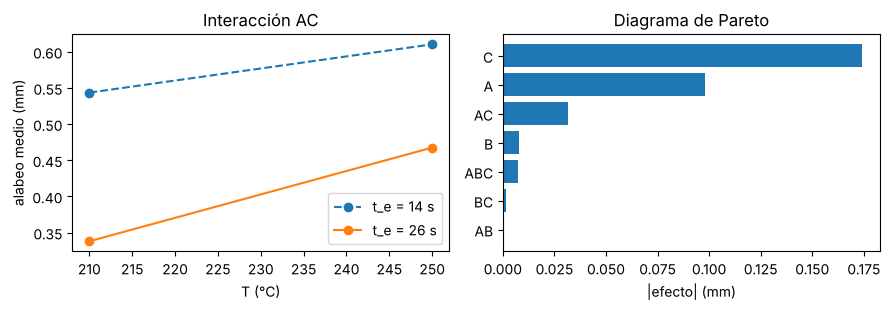

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
yb = Y23.mean(1)
for c, est in [(-1, "--"), (1, "-")]:
    s = U[:, 2] == c
    ax[0].plot([210, 250], [yb[s & (U[:, 0] == -1)].mean(), yb[s & (U[:, 0] == 1)].mean()], est, marker="o",
               label=f"t_e = {14 if c < 0 else 26} s")
ax[0].set_xlabel("T (°C)"); ax[0].set_ylabel("alabeo medio (mm)"); ax[0].legend(); ax[0].set_title("Interacción AC")
orden = np.argsort(np.abs(ef))
ax[1].barh(np.array(etq)[orden], np.abs(ef)[orden]); ax[1].set_xlabel("|efecto| (mm)"); ax[1].set_title("Diagrama de Pareto")
plt.tight_layout(); plt.show()

### 2.2 Hipercubo latino
**Ejercicio 5.** Escribe `es_hipercubo_latino(U)` que, para una matriz $n\times d$ con valores en $[0,1)$, compruebe que en cada columna hay exactamente un punto en cada estrato $[k/n,(k+1)/n)$ (definición 2.12).

In [16]:
def es_hipercubo_latino(U):
    # TU CÓDIGO
    raise NotImplementedError

In [17]:
# Comprobación
es_hipercubo_latino = usar_si_falta(es_hipercubo_latino, "es_hipercubo_latino", np.array([[0.1], [0.6]]))
lhs = qmc.LatinHypercube(d=3, rng=np.random.default_rng(0)).random(10)
assert es_hipercubo_latino(lhs)
assert not es_hipercubo_latino(np.random.default_rng(0).random((10, 3))), "Un muestreo uniforme casi nunca es LHS"
def dist_min(Z):
    D = np.sqrt(((Z[:, None] - Z[None])**2).sum(-1)); return D[np.triu_indices(len(Z), 1)].min()
mejor = qmc.LatinHypercube(d=3, optimization="random-cd", rng=np.random.default_rng(0)).random(10)
alea = [dist_min(np.random.default_rng(s).random((10, 3))) for s in range(200)]
lhss = [dist_min(qmc.LatinHypercube(d=3, rng=np.random.default_rng(s)).random(10)) for s in range(200)]
ok(f"distancia mínima media (10 puntos, d = 3): uniforme {np.mean(alea):.3f}, LHS {np.mean(lhss):.3f}; "
   f"discrepancia centrada LHS {qmc.discrepancy(lhs):.4f} -> optimizado {qmc.discrepancy(mejor):.4f}")

[pendiente] Ejercicio «es_hipercubo_latino» sin resolver: se usa la solución de referencia para continuar.
Correcto: distancia mínima media (10 puntos, d = 3): uniforme 0.168, LHS 0.228; discrepancia centrada LHS 0.0154 -> optimizado 0.0105


**Reducción de varianza (teorema 2.13).** Estimamos el coste medio del proceso en todo el dominio con $n=20$ puntos, por Monte Carlo simple y por LHS, repitiendo 500 veces.

In [18]:
verd = coste_real(a_fisicas(np.random.default_rng(99).random((400_000, 3)))).mean()
mc  = [coste_real(a_fisicas(np.random.default_rng(s).random((20, 3)))).mean() for s in range(500)]
lh  = [coste_real(a_fisicas(qmc.LatinHypercube(d=3, rng=np.random.default_rng(s)).random(20))).mean() for s in range(500)]
print(f"media verdadera ≈ {verd:.4f}; desv. típica MC = {np.std(mc):.4f}, LHS = {np.std(lh):.4f} "
      f"(cociente de varianzas {np.var(lh)/np.var(mc):.2f})")

media verdadera ≈ 0.8414; desv. típica MC = 0.0247, LHS = 0.0129 (cociente de varianzas 0.27)


### 2.3 Superficie de respuesta
Con $t_e=20$ s fijo, un diseño central compuesto en $(T,P)$ ($2^2$ factorial, 4 puntos axiales con $\alpha=\sqrt2$ y 3 centrales) alrededor de $(220, 65)$ con semirrangos $(15, 15)$. Ajustamos el modelo de segundo orden $\hat y = b_0 + b^\top u + u^\top B u$ al coste observado.

**Ejercicio 6.** Escribe `punto_estacionario(b, B)` que devuelva $u_s=-\tfrac12 B^{-1}b$ (proposición 2.10).

In [19]:
def punto_estacionario(b, B):
    # TU CÓDIGO
    raise NotImplementedError

In [20]:
# Comprobación
punto_estacionario = usar_si_falta(punto_estacionario, "punto_estacionario", np.zeros(2), np.eye(2))
a = np.sqrt(2)
Uc = np.array([[-1, -1], [1, -1], [-1, 1], [1, 1], [-a, 0], [a, 0], [0, -a], [0, a], [0, 0], [0, 0], [0, 0]])
Xc = np.column_stack([220 + 15*Uc[:, 0], 65 + 15*Uc[:, 1], np.full(len(Uc), 20.0)])
rng = np.random.default_rng(5)
yc = np.mean([experimento(Xc, rng, n_lote=1000)[0] for _ in range(3)], axis=0)   # 3 lotes de 1000 piezas
Phi = np.column_stack([np.ones(len(Uc)), Uc, Uc[:, 0]**2, Uc[:, 1]**2, Uc[:, 0]*Uc[:, 1]])
beta = np.linalg.lstsq(Phi, yc, rcond=None)[0]
b = beta[1:3]; B = np.array([[beta[3], beta[5]/2], [beta[5]/2, beta[4]]])
us = punto_estacionario(b, B)
assert np.allclose(2 * B @ us + b, 0), "En el punto estacionario el gradiente se anula"
lam = np.linalg.eigvalsh(B)
xs = np.array([220 + 15*us[0], 65 + 15*us[1], 20.0])
ok(f"u_s = {us}, autovalores de B = {lam} -> {'mínimo' if np.all(lam > 0) else 'silla o máximo'}; "
   f"x_s = ({xs[0]:.1f} °C, {xs[1]:.1f} MPa); coste real en x_s = {coste_real(xs)[0]:.4f}")

[pendiente] Ejercicio «punto_estacionario» sin resolver: se usa la solución de referencia para continuar.
Correcto: u_s = [ 0.5562 -0.3734], autovalores de B = [0.0058 0.0392] -> mínimo; x_s = (228.3 °C, 59.4 MPa); coste real en x_s = 0.7920


## Parte 3 · Modelos sustitutos (tema 3)

### 3.1 Un proceso gaussiano desde cero
**Ejercicio 7.** Escribe `gp_posterior(Xtr, ytr, Xte, ell, sf, sn)` con núcleo exponencial cuadrático $k(x,x')=\sigma_f^2\exp(-\|x-x'\|^2/2\ell^2)$ y ruido $\sigma_n^2$. Usa la factorización de Cholesky (observación 3.9 de los apuntes) y devuelve la media y la **varianza de $f$** (sin el ruido) en `Xte`. Puedes usar la función auxiliar `k_se` de abajo.

In [21]:
def k_se(A, B, ell, sf):
    d2 = ((A[:, None, :] - B[None, :, :])**2).sum(-1)
    return sf**2 * np.exp(-0.5 * d2 / ell**2)

def gp_posterior(Xtr, ytr, Xte, ell, sf, sn):
    # TU CÓDIGO
    raise NotImplementedError

In [22]:
# Comprobación
gp_posterior = usar_si_falta(gp_posterior, "gp_posterior", np.zeros((1, 1)), np.zeros(1), np.zeros((1, 1)), 1., 1., 0.1)
Xa, ya = np.array([[0.0], [1.0]]), np.array([1.0, 0.0])
mu, var = gp_posterior(Xa, ya, np.array([[0.5]]), 1.0, 1.0, 0.0)
assert abs(mu[0] - 0.5494) < 1e-3 and abs(var[0] - 0.0305) < 1e-3, "Ejemplo 3.7: mu = 0,5493, var = 0,0305"
gp_sk = GaussianProcessRegressor(Ck(1.0, "fixed") * RBF(1.0, "fixed"), alpha=1e-10, optimizer=None).fit(Xa, ya)
m2, s2 = gp_sk.predict(np.array([[0.5]]), return_std=True)
assert abs(m2[0] - mu[0]) < 1e-6 and abs(s2[0]**2 - var[0]) < 1e-6
ok(f"μ(0,5) = {mu[0]:.4f}, σ²(0,5) = {var[0]:.4f} (coincide con scikit-learn)")

[pendiente] Ejercicio «gp_posterior» sin resolver: se usa la solución de referencia para continuar.
Correcto: μ(0,5) = 0.5493, σ²(0,5) = 0.0305 (coincide con scikit-learn)


**Ejercicio 8.** Escribe `log_verosimilitud_marginal(Xtr, ytr, ell, sf, sn)` (ecuación 3.1): $-\tfrac12 y^\top K_y^{-1}y-\sum_i\log L_{ii}-\tfrac n2\log 2\pi$. La usaremos para elegir la longitud de escala de un sustituto 1D del alabeo frente al tiempo de enfriamiento.

In [23]:
def log_verosimilitud_marginal(Xtr, ytr, ell, sf, sn):
    # TU CÓDIGO
    raise NotImplementedError

[pendiente] Ejercicio «log_verosimilitud_marginal» sin resolver: se usa la solución de referencia para continuar.
σ_n = 0.100: máximos locales en ℓ = [np.float64(0.962)], máximo global en ℓ = 0.032
σ_n = 0.165: máximos locales en ℓ = [np.float64(0.872)], máximo global en ℓ = 0.872
Correcto: con el ruido correcto, ℓ óptima = 0.872; con σ_n demasiado pequeño gana una ℓ diminuta que «explica» el ruido como señal


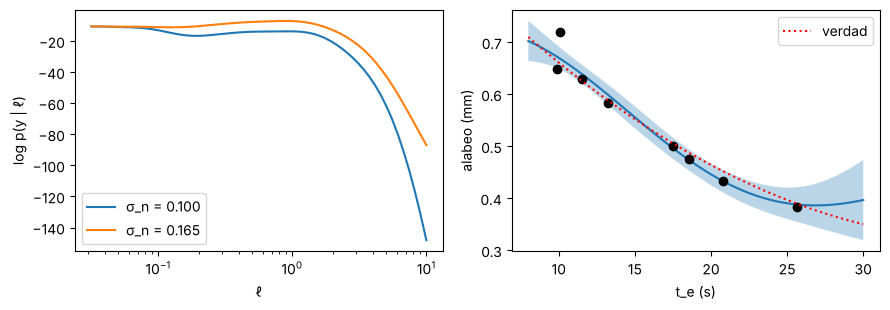

In [24]:
# Comprobación
log_verosimilitud_marginal = usar_si_falta(log_verosimilitud_marginal, "log_verosimilitud_marginal",
                                           np.zeros((1, 1)), np.zeros(1), 1., 1., 0.1)
assert abs(log_verosimilitud_marginal(np.zeros((1, 1)), np.array([1.0]), 1.0, 1.0, 0.0) - (-0.5 - 0.5*np.log(2*np.pi))) < 1e-6
rng = np.random.default_rng(3)
t1 = np.sort(rng.uniform(8, 30, 8)); x1 = np.column_stack([np.full(8, 230.), np.full(8, 60.), t1])
w1 = alabeo(x1) + rng.normal(0, 0.018, 8)
z1 = ((t1 - 19) / 11)[:, None]; yw = (w1 - w1.mean()) / w1.std()
ells = np.logspace(-1.5, 1, 60)
sn_ok = 0.018 / w1.std()                         # ruido real (0,018 mm) en unidades tipificadas
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for sn in [0.1, sn_ok]:
    lml = np.array([log_verosimilitud_marginal(z1, yw, l, 1.0, sn) for l in ells])
    loc = [i for i in range(1, len(ells) - 1) if lml[i] > lml[i - 1] and lml[i] > lml[i + 1]]
    print(f"σ_n = {sn:.3f}: máximos locales en ℓ = {[round(ells[i], 3) for i in loc]}, máximo global en ℓ = {ells[np.argmax(lml)]:.3f}")
    ax[0].semilogx(ells, lml, label=f"σ_n = {sn:.3f}")
l_opt = ells[np.argmax([log_verosimilitud_marginal(z1, yw, l, 1.0, sn_ok) for l in ells])]
ok(f"con el ruido correcto, ℓ óptima = {l_opt:.3f}; con σ_n demasiado pequeño gana una ℓ diminuta que «explica» el ruido como señal")
ax[0].set_xlabel("ℓ"); ax[0].set_ylabel("log p(y | ℓ)"); ax[0].legend()
zz = np.linspace(-1, 1, 200)[:, None]
m, v = gp_posterior(z1, yw, zz, l_opt, 1.0, sn_ok)
tt = 19 + 11 * zz[:, 0]; esc = w1.std()
ax[1].plot(tt, w1.mean() + esc*m); ax[1].fill_between(tt, w1.mean() + esc*(m - 2*np.sqrt(v)), w1.mean() + esc*(m + 2*np.sqrt(v)), alpha=0.3)
ax[1].plot(t1, w1, "ko"); ax[1].plot(tt, alabeo(np.column_stack([np.full(200, 230.), np.full(200, 60.), tt])), "r:", label="verdad")
ax[1].set_xlabel("t_e (s)"); ax[1].set_ylabel("alabeo (mm)"); ax[1].legend(); plt.tight_layout(); plt.show()

### 3.2 Tres sustitutos del coste con 20 ensayos
Comparamos, con los mismos 20 ensayos de un hipercubo latino: (a) regresión cuadrática, (b) proceso gaussiano Matérn 5/2 con relevancia automática (ARD) y ruido estimado, (c) un *ensemble* de 5 redes neuronales. Medimos el error en 2000 puntos de prueba y la **cobertura** del intervalo del 95 %.

In [25]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor

def ajusta_gp(Z, y, semilla=0):
    k = Ck(1.0, (1e-2, 1e2)) * Matern(length_scale=np.full(Z.shape[1], 0.5), length_scale_bounds=(0.05, 20.0), nu=2.5) \
        + WhiteKernel(1e-2, (1e-6, 1.0))
    return GaussianProcessRegressor(k, normalize_y=True, n_restarts_optimizer=2, random_state=semilla).fit(Z, y)

def sustitutos(semilla):
    "Ajusta polinomio cuadrático y PG con 20 ensayos LHS; devuelve predicciones en 2000 puntos de prueba."
    rng = np.random.default_rng(semilla)
    Ztr = qmc.LatinHypercube(d=3, rng=rng).random(20); ytr = experimento(a_fisicas(Ztr), rng)[0]
    Zte = rng.random((2000, 3)); yte = coste_real(a_fisicas(Zte))
    pol = PolynomialFeatures(2); P_tr = pol.fit_transform(2*Ztr - 1); P_te = pol.transform(2*Zte - 1)
    lr = LinearRegression().fit(P_tr, ytr)
    H = P_tr @ np.linalg.pinv(P_tr.T @ P_tr) @ P_tr.T
    e_loo = (ytr - lr.predict(P_tr)) / (1 - np.diag(H))          # proposición 3.1
    gp = ajusta_gp(Ztr, ytr, semilla); m_gp, s_gp = gp.predict(Zte, return_std=True)
    return dict(Ztr=Ztr, ytr=ytr, Zte=Zte, yte=yte, pol=(lr.predict(P_te), np.sqrt(np.mean(e_loo**2))), gp=(m_gp, s_gp), kernel=gp.kernel_)
S10 = sustitutos(10)
print("núcleo ajustado (semilla 10):", S10["kernel"])

núcleo ajustado (semilla 10): 1.24**2 * Matern(length_scale=[0.478, 0.557, 0.343], nu=2.5) + WhiteKernel(noise_level=1e-06)


**Ejercicio 9.** Un *ensemble* da $M$ medias $\mu_m(x)$ y desviaciones $\sigma_m(x)$. Escribe `mezcla_ensemble(mus, sigmas)` que devuelva la media y la desviación típica de la mezcla uniforme (proposición 3.12): $\mu=\frac1M\sum\mu_m$, $\sigma^2=\frac1M\sum(\sigma_m^2+\mu_m^2)-\mu^2$. Aquí cada red se entrena con MSE, así que $\sigma_m$ es la desviación de sus residuos de validación cruzada (constante).

In [26]:
def mezcla_ensemble(mus, sigmas):
    # TU CÓDIGO
    raise NotImplementedError

In [27]:
# Comprobación
mezcla_ensemble = usar_si_falta(mezcla_ensemble, "mezcla_ensemble", [[0.]], [[1.]])
mu_t, s_t = mezcla_ensemble([[1.0], [2.0], [3.0]], [[0.5], [0.5], [0.5]])
assert abs(mu_t[0] - 2.0) < 1e-12 and abs(s_t[0] - np.sqrt(0.25 + 2/3)) < 1e-12, "Ejercicio 3.6: σ² = 0,25 + 2/3"
def ensemble(S, M=5):
    Ztr, ytr, Zte = S["Ztr"], S["ytr"], S["Zte"]; mus, sig = [], []
    for mm in range(M):
        idx = np.random.default_rng(100 + mm).integers(0, 20, 20)            # remuestreo bootstrap
        red = MLPRegressor(hidden_layer_sizes=(32, 32), activation="tanh", alpha=1e-3, max_iter=4000,
                           learning_rate_init=0.01, random_state=mm).fit(Ztr[idx], (ytr[idx] - ytr.mean()) / ytr.std())
        mus.append(ytr.mean() + ytr.std() * red.predict(Zte))
        fuera = np.setdiff1d(np.arange(20), idx)                               # ejemplos no usados por esta red
        res = ytr[fuera] - (ytr.mean() + ytr.std() * red.predict(Ztr[fuera]))
        sig.append(np.full(len(Zte), np.sqrt(np.mean(res**2))))
    return mezcla_ensemble(mus, sig)
tabla = {"cuadrático": [], "PG Matérn 5/2 ARD": [], "ensemble de 5 redes": []}
for sem in range(10, 15):
    S = S10 if sem == 10 else sustitutos(sem)
    for nom, (m, s) in zip(tabla, [S["pol"], S["gp"], ensemble(S)]):
        tabla[nom].append((np.sqrt(np.mean((m - S["yte"])**2)), np.mean(np.abs(m - S["yte"]) <= 1.96 * s)))
print(f"{'sustituto':<22}{'RMSE medio (€)':>15}{'cobertura 95 % media':>22}   (5 repeticiones)")
for nom, v in tabla.items():
    v = np.array(v); print(f"{nom:<22}{v[:, 0].mean():15.4f}{100*v[:, 1].mean():21.1f} %")
ok("comparación de sustitutos")

[pendiente] Ejercicio «mezcla_ensemble» sin resolver: se usa la solución de referencia para continuar.


sustituto              RMSE medio (€)  cobertura 95 % media   (5 repeticiones)
cuadrático                     0.0532                 92.4 %
PG Matérn 5/2 ARD              0.0628                 84.0 %
ensemble de 5 redes            0.0738                 94.2 %
Correcto: comparación de sustitutos


### 3.3 Una PINN en miniatura (tema 3, §3.6)
La superficie de la pieza se enfría según la ley de Newton $\dot T=-k\,(T-T_m)$ con $T_m=40$ °C. Con solo 4 medidas de temperatura ruidosas, una red $T_\theta(t)$ que además debe cumplir la ecuación (residuo en 50 puntos de colocación) **identifica** $k$. Con $k$ se calcula cuánto tarda la pieza en llegar a la temperatura de expulsión de 90 °C.

In [28]:
import torch
torch.manual_seed(0); torch.set_num_threads(1)
k_real, Tm, T0 = 0.12, 40.0, 230.0
t_med = np.array([2.0, 5.0, 9.0, 14.0]); rng = np.random.default_rng(4)
T_med = Tm + (T0 - Tm) * np.exp(-k_real * t_med) + rng.normal(0, 1.5, 4)
ts = torch.tensor(t_med / 30, dtype=torch.float32)[:, None]; Ts = torch.tensor(T_med / 100, dtype=torch.float32)[:, None]
tc = torch.linspace(0, 1, 50)[:, None].requires_grad_(True)
red = torch.nn.Sequential(torch.nn.Linear(1, 20), torch.nn.Tanh(), torch.nn.Linear(20, 20), torch.nn.Tanh(), torch.nn.Linear(20, 1))
log_k = torch.tensor(np.log(0.05), dtype=torch.float32, requires_grad=True)       # valor inicial k = 0,05
opt = torch.optim.Adam(list(red.parameters()) + [log_k], lr=5e-3)
for it in range(4000):
    T_c = red(tc); dT = torch.autograd.grad(T_c.sum(), tc, create_graph=True)[0]       # dT/d(t/30) en unidades de 100 °C
    resid = dT / 30 + torch.exp(log_k) * (T_c - Tm / 100)                              # residuo de la EDO
    T_0 = red(torch.zeros(1, 1))
    perdida = ((red(ts) - Ts)**2).mean() + (resid**2).mean() * 30**2 + ((T_0 - T0 / 100)**2).mean()
    opt.zero_grad(); perdida.backward(); opt.step()
k_est = torch.exp(log_k).item()
t_exp = lambda k: np.log((T0 - Tm) / (90 - Tm)) / k
print(f"k estimada = {k_est:.4f} s⁻¹ (real {k_real}); tiempo hasta 90 °C: {t_exp(k_est):.2f} s (real {t_exp(k_real):.2f} s)")

k estimada = 0.1181 s⁻¹ (real 0.12); tiempo hasta 90 °C: 11.30 s (real 11.13 s)


## Parte 4 · Optimización bayesiana (tema 4)

**Ejercicio 10.** Escribe `mejora_esperada(mu, sigma, f_mejor)` para **minimización** (teorema 4.4): $\mathrm{EI}=(f^*-\mu)\Phi(z)+\sigma\varphi(z)$, $z=(f^*-\mu)/\sigma$. Si $\sigma=0$, devuelve $\max(f^*-\mu,0)$. Debe aceptar arrays.

In [29]:
def mejora_esperada(mu, sigma, f_mejor):
    # TU CÓDIGO
    raise NotImplementedError

In [30]:
# Comprobación
mejora_esperada = usar_si_falta(mejora_esperada, "mejora_esperada", np.array([0.]), np.array([1.]), 0.)
mu_c, s_c = np.array([0.78, 0.83, 0.95]), np.array([0.01, 0.06, 0.10])
ei = mejora_esperada(mu_c, s_c, 0.80)
assert np.allclose(ei, [0.020085, 0.011868, 0.002931], atol=2e-6), "Ejemplo 4.6"
z = np.random.default_rng(0).standard_normal(1_000_000)
assert abs(np.maximum(0.80 - (0.83 + 0.06*z), 0).mean() - ei[1]) < 1e-4, "Debe coincidir con Monte Carlo"
assert mejora_esperada(np.array([1.0]), np.array([0.0]), 0.8)[0] == 0
ok(f"EI en A, B, C = {ei}")

[pendiente] Ejercicio «mejora_esperada» sin resolver: se usa la solución de referencia para continuar.
Correcto: EI en A, B, C = [0.0201 0.0119 0.0029]


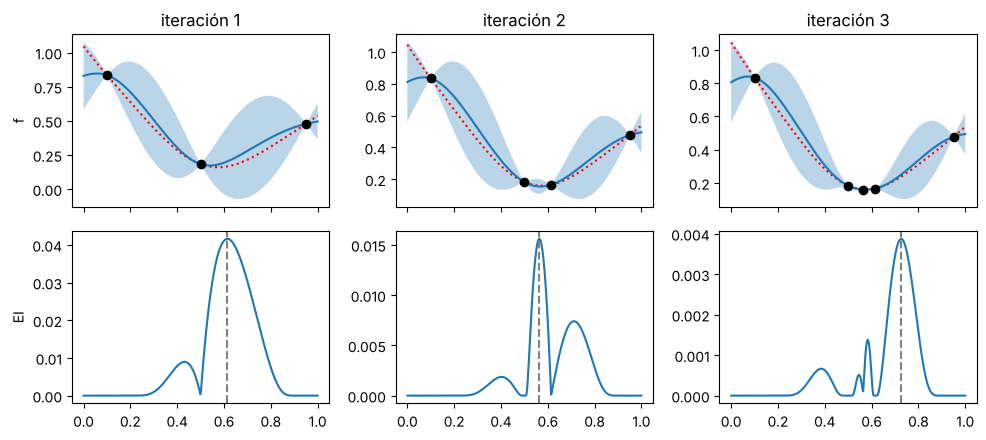

In [31]:
# Bucle de optimización bayesiana en 1D (figura 4.1 de los apuntes) sobre una función sintética
g1 = lambda z: 0.20 + 2.2 * (z - 0.62)**2 + 0.05 * np.sin(9 * z)
Z1 = np.array([[0.1], [0.5], [0.95]])
fig, axs = plt.subplots(2, 3, figsize=(10, 4.5), sharex=True)
for it in range(3):
    gp1 = GaussianProcessRegressor(Ck(1.0, "fixed") * Matern(0.25, "fixed", nu=2.5), alpha=1e-6, normalize_y=True).fit(Z1, g1(Z1[:, 0]))
    zz = np.linspace(0, 1, 400)[:, None]; m, s = gp1.predict(zz, return_std=True)
    a = mejora_esperada(m, s, g1(Z1[:, 0]).min()); znew = zz[np.argmax(a)]
    axs[0, it].plot(zz, g1(zz[:, 0]), "r:"); axs[0, it].plot(zz, m); axs[0, it].fill_between(zz[:, 0], m - 2*s, m + 2*s, alpha=0.3)
    axs[0, it].plot(Z1, g1(Z1[:, 0]), "ko"); axs[0, it].set_title(f"iteración {it + 1}")
    axs[1, it].plot(zz, a); axs[1, it].axvline(znew[0], ls="--", c="gray")
    Z1 = np.vstack([Z1, znew])
axs[1, 0].set_ylabel("EI"); axs[0, 0].set_ylabel("f"); plt.tight_layout(); plt.show()

**Ejercicio 11.** Escribe `ei_restringida(mu_f, s_f, f_mejor, mu_c, s_c, limite)` $=\mathrm{EI}(x)\cdot\Pr[c(x)\le \text{limite}]$ con $c\sim\mathcal N(\mu_c,s_c^2)$ (proposición 4.9).

In [32]:
def ei_restringida(mu_f, s_f, f_mejor, mu_c, s_c, limite):
    # TU CÓDIGO
    raise NotImplementedError

In [33]:
# Comprobación
ei_restringida = usar_si_falta(ei_restringida, "ei_restringida", np.array([0.]), np.array([1.]), 0., np.array([0.]), np.array([1.]), 0.)
v = ei_restringida(np.array([0.78]), np.array([0.01]), 0.80, np.array([0.44]), np.array([0.02]), 0.45)
assert abs(v[0] - 0.020085 * norm.cdf(0.5)) < 1e-6, "Ejercicio 4.3"
ok(f"EI restringida = {v[0]:.6f}")

[pendiente] Ejercicio «ei_restringida» sin resolver: se usa la solución de referencia para continuar.
Correcto: EI restringida = 0.013888


### 4.1 El optimizador completo
La función `optimiza_inyectora` implementa el algoritmo 4.1: 10 ensayos iniciales (hipercubo latino) y después, en cada iteración, ajusta dos procesos gaussianos (coste y alabeo), maximiza la EI restringida sobre 4000 candidatos aleatorios más perturbaciones de los puntos ya ensayados, y ejecuta el lote propuesto. Con `q > 1` propone lotes con el «creyente del kriging» (§4.7).

Dos detalles importan mucho (observación 4.8 de los apuntes):
* `predict(..., return_std=True)` de scikit-learn devuelve la desviación de una **nueva observación** (incluye el ruido del `WhiteKernel`). Para la EI y para la probabilidad de cumplir la restricción hay que usar la de la **función latente** $f$; si no, la EI nunca se anula en los puntos ya ensayados y el algoritmo repite una y otra vez el mismo ajuste.
* La **recomendación final** minimiza la media posterior del coste en todo el dominio entre los puntos con $\Pr[w\le 0{,}45]\ge 0{,}8$, y no el mejor coste observado (maldición del ganador).

In [34]:
def latente(gp, Z):
    "Media y desviación típica de la función latente f (sin el ruido de observación)."
    m, s = gp.predict(Z, return_std=True)
    ruido = gp.kernel_.k2.noise_level * gp._y_train_std**2
    return m, np.sqrt(np.maximum(s**2 - ruido, 1e-12))

def propone(gp_f, gp_c, Z, rng, f_mejor, n_cand=4000):
    cand = np.vstack([rng.random((n_cand, 3)), np.clip(Z[rng.integers(len(Z), size=500)] + rng.normal(0, 0.05, (500, 3)), 0, 1)])
    mf, sf_ = latente(gp_f, cand); mc, sc = latente(gp_c, cand)
    a = ei_restringida(mf, sf_, f_mejor, mc, sc, W_MAX) if np.isfinite(f_mejor) else norm.cdf((W_MAX - mc) / sc)
    return cand[np.argmax(a)], a.max()

def recomienda(gp_f, gp_c, Z, umbral=0.8, semilla=0):
    C = np.vstack([Z, np.random.default_rng(semilla).random((20000, 3))])
    mf, _ = latente(gp_f, C); mc, sc = latente(gp_c, C)
    pf = norm.cdf((W_MAX - mc) / sc)
    return a_fisicas(C[np.argmin(np.where(pf >= umbral, mf, np.inf))])[0]

def optimiza_inyectora(semilla, n_ini=10, n_iter=20, q=1):
    rng = np.random.default_rng(semilla)
    Z = qmc.LatinHypercube(d=3, rng=rng).random(n_ini)
    yf, _, yc = experimento(a_fisicas(Z), rng)
    traza = []
    for it in range(n_iter // q):
        gp_f, gp_c = ajusta_gp(Z, yf, semilla), ajusta_gp(Z, yc, semilla)
        mf, _ = latente(gp_f, Z); mc, sc = latente(gp_c, Z)
        f_mejor = np.min(np.where(norm.cdf((W_MAX - mc) / sc) >= 0.5, mf, np.inf))
        lote, Zf, yff, ycf = [], Z.copy(), yf.copy(), yc.copy()
        for j in range(q):                                     # creyente del kriging
            z, a = propone(gp_f, gp_c, Zf, rng, f_mejor)
            lote.append(z); traza.append(a)
            if j < q - 1:
                Zf = np.vstack([Zf, z]); yff = np.append(yff, gp_f.predict(z[None])); ycf = np.append(ycf, gp_c.predict(z[None]))
                gp_f = GaussianProcessRegressor(gp_f.kernel_, normalize_y=True, optimizer=None).fit(Zf, yff)
                gp_c = GaussianProcessRegressor(gp_c.kernel_, normalize_y=True, optimizer=None).fit(Zf, ycf)
        lote = np.array(lote)
        a_f, _, a_c = experimento(a_fisicas(lote), rng)
        Z = np.vstack([Z, lote]); yf = np.append(yf, a_f); yc = np.append(yc, a_c)
    gp_f, gp_c = ajusta_gp(Z, yf, semilla), ajusta_gp(Z, yc, semilla)
    return dict(Z=Z, yf=yf, yc=yc, rec=recomienda(gp_f, gp_c, Z, semilla=semilla), traza=np.array(traza), gp_f=gp_f, gp_c=gp_c)

def lhs_inyectora(semilla, n=30):
    "Alternativa sin bucle: los 30 ensayos de golpe (hipercubo latino) y la misma recomendación con PG."
    rng = np.random.default_rng(1000 + semilla)
    Z = qmc.LatinHypercube(d=3, rng=rng).random(n); yf, _, yc = experimento(a_fisicas(Z), rng)
    return dict(Z=Z, rec=recomienda(ajusta_gp(Z, yf, semilla), ajusta_gp(Z, yc, semilla), Z, semilla=semilla))

def resumen(r):
    X = a_fisicas(r["Z"])
    return coste_real(r["rec"])[0] - C_OPT, alabeo(r["rec"])[0], np.mean(alabeo(X) > W_MAX), coste_real(X).mean()

t0 = time.time()
res = [optimiza_inyectora(s) for s in range(10)]
lhs30 = [lhs_inyectora(s) for s in range(10)]
RB, RL = np.array([resumen(r) for r in res]), np.array([resumen(r) for r in lhs30])
print(f"(10 repeticiones, {time.time() - t0:.0f} s)")
print(f"{'':<26}{'regret mediano':>15}{'regret máx.':>12}{'alabeo rec. máx.':>17}{'lotes fuera esp.':>17}{'coste medio lotes':>18}")
for nom, R in [("optimización bayesiana", RB), ("hipercubo latino + PG", RL)]:
    print(f"{nom:<26}{np.median(R[:, 0]):15.4f}{R[:, 0].max():12.4f}{R[:, 1].max():17.3f}{100*R[:, 2].mean():16.0f} %{R[:, 3].mean():18.4f}")
print(f"(óptimo {C_OPT:.4f} €/pieza; regret en €/pieza)")

(10 repeticiones, 29 s)
                           regret mediano regret máx. alabeo rec. máx. lotes fuera esp. coste medio lotes
optimización bayesiana             0.0066      0.0219            0.448              39 %            0.8278
hipercubo latino + PG              0.0170      0.0322            0.451              68 %            0.8408
(óptimo 0.7782 €/pieza; regret en €/pieza)


Recomendación (semilla 0): T = 200.0 °C, P = 84.4 MPa, t_e = 17.94 s -> coste real 0.8001, alabeo real 0.447
Regla de Jones et al. (EI máx. < 1 % del mejor): se cumple por primera vez en el ensayo 13


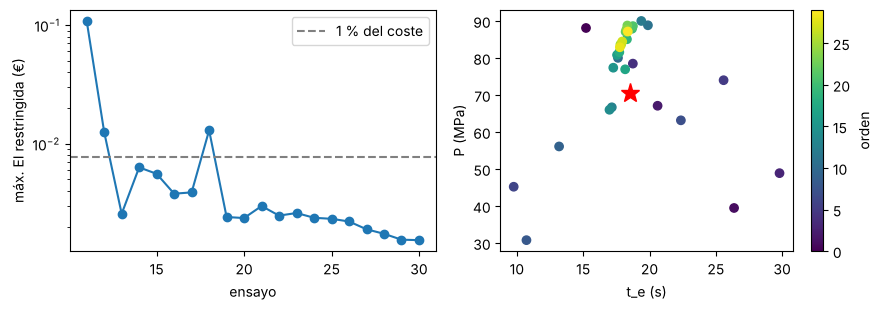

In [35]:
r0 = res[0]
print("Recomendación (semilla 0): T = %.1f °C, P = %.1f MPa, t_e = %.2f s" % tuple(r0["rec"]),
      "-> coste real %.4f, alabeo real %.3f" % (coste_real(r0["rec"])[0], alabeo(r0["rec"])[0]))
umbral_parada = 0.01 * C_OPT
it_parada = next((i for i, a in enumerate(r0["traza"]) if a < umbral_parada), None)
print(f"Regla de Jones et al. (EI máx. < 1 % del mejor): se cumple por primera vez en el ensayo {11 + it_parada}" if it_parada is not None else "La regla de parada no se activa")
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(np.arange(11, 31), r0["traza"], "o-"); ax[0].set_yscale("log"); ax[0].set_xlabel("ensayo"); ax[0].set_ylabel("máx. EI restringida (€)")
ax[0].axhline(umbral_parada, ls="--", c="gray", label="1 % del coste"); ax[0].legend()
Xr = a_fisicas(r0["Z"])
sc = ax[1].scatter(Xr[:, 2], Xr[:, 1], c=np.arange(len(Xr)), cmap="viridis"); ax[1].plot(*X_OPT[[2, 1]], "r*", ms=14)
ax[1].set_xlabel("t_e (s)"); ax[1].set_ylabel("P (MPa)"); plt.colorbar(sc, ax=ax[1], label="orden"); plt.tight_layout(); plt.show()

In [36]:
# Lotes de dos ensayos por turno (q = 2, creyente del kriging): mismo presupuesto, la mitad de rondas
t0 = time.time()
RQ = np.array([resumen(optimiza_inyectora(s, q=2)) for s in range(10)])
print(f"Regret mediano con lotes q = 2: {np.median(RQ[:, 0]):.4f} €/pieza en 10 rondas "
      f"(q = 1: {np.median(RB[:, 0]):.4f} en 20 rondas) · {time.time() - t0:.0f} s")

Regret mediano con lotes q = 2: 0.0044 €/pieza en 10 rondas (q = 1: 0.0066 en 20 rondas) · 15 s


### 4.2 Dos objetivos: defectos frente a tiempo de ciclo
**Ejercicio 12.** Escribe `no_dominados(F)` que, para una matriz $n\times m$ de objetivos (todos a minimizar), devuelva un vector booleano que marque los puntos **no dominados** (definición 4.10).

**Ejercicio 13.** Escribe `hipervolumen_2d(F, ref)`: área dominada por los puntos no dominados de `F` y acotada por el punto de referencia `ref` (definición 4.11).

In [37]:
def no_dominados(F):
    # TU CÓDIGO
    raise NotImplementedError

def hipervolumen_2d(F, ref):
    # TU CÓDIGO
    raise NotImplementedError

[pendiente] Ejercicio «no_dominados» sin resolver: se usa la solución de referencia para continuar.
[pendiente] Ejercicio «hipervolumen_2d» sin resolver: se usa la solución de referencia para continuar.
Correcto: 39 de 183 ensayos factibles son no dominados; HV respecto a (20 %, 45 s) = 334.6


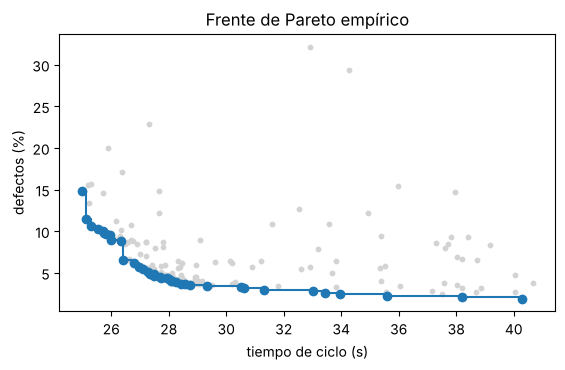

In [38]:
# Comprobación
no_dominados = usar_si_falta(no_dominados, "no_dominados", np.array([[0., 1.]]))
hipervolumen_2d = usar_si_falta(hipervolumen_2d, "hipervolumen_2d", np.array([[0., 1.]]), np.array([2., 2.]))
F6 = np.array([[2.0, 30], [3.0, 26], [5.0, 22], [4.0, 27], [8.0, 21], [2.5, 32]])    # ejercicio 4.5: (defectos %, ciclo s)
assert np.array_equal(no_dominados(F6), [True, True, True, False, True, False])
assert abs(hipervolumen_2d(F6, np.array([10.0, 35])) - 90.0) < 1e-9, "Ejercicio 4.5: HV = 90"
X_all = a_fisicas(np.vstack([r["Z"] for r in res]))
cumple = alabeo(X_all) <= W_MAX
F = np.column_stack([100 * tasa_defectos(X_all), t_ciclo(X_all)])[cumple]
nd = no_dominados(F)
ok(f"{nd.sum()} de {len(F)} ensayos factibles son no dominados; HV respecto a (20 %, 45 s) = {hipervolumen_2d(F, np.array([20., 45.])):.1f}")
plt.scatter(F[:, 1], F[:, 0], s=10, c="lightgray"); o = np.argsort(F[nd, 1])
plt.step(F[nd, 1][o], F[nd, 0][o], "o-", where="post"); plt.xlabel("tiempo de ciclo (s)"); plt.ylabel("defectos (%)"); plt.title("Frente de Pareto empírico"); plt.show()

## Parte 5 · Caso de estudio: un hormigón con menos CO₂ (tema 5)

Variables: relación agua/conglomerante $a/c\in[0{,}35;0{,}60]$, fracción de cemento sustituida por cenizas volantes $s\in[0;0{,}40]$ y contenido de conglomerante $b\in[280;450]$ kg/m³. Restricción conocida (barata): agua $=(a/c)\,b\in[160;195]$ kg/m³. Objetivo **conocido**: potencial de calentamiento global $\mathrm{GWP}=0{,}93\,b(1-s)+0{,}03\,bs+45$ kg CO₂e/m³. Restricción **cara**: resistencia media a 28 días $f_{28}\ge f_{ck}+1{,}645\,\sigma_p=30+1{,}645\cdot4=36{,}58$ MPa. Cada ensayo se rompe a los 7 y a los 28 días; ruido de 2 MPa. Como en la Parte 1, las fórmulas son sintéticas.

In [39]:
LIMH = np.array([[0.35, 0.60], [0.0, 0.40], [280., 450.]])
F_OBJ = 30 + 1.645 * 4
def a_fis_h(z): return LIMH[:, 0] + np.atleast_2d(z) * (LIMH[:, 1] - LIMH[:, 0])
def f28(x):
    x = np.atleast_2d(x); ac, s, b = x.T
    return 105.0 * 8.0**(-ac) * (1 - 0.5*s - 1.2*s**2) * (1 + 0.0005*(b - 350))
def f7(x):
    x = np.atleast_2d(x); return f28(x) * (0.68 - 0.45 * x[:, 1])
def gwp(x):
    x = np.atleast_2d(x); ac, s, b = x.T
    return 0.93*b*(1 - s) + 0.03*b*s + 45.0
def agua_ok(x):
    x = np.atleast_2d(x); w = x[:, 0] * x[:, 2]; return (w >= 160) & (w <= 195)
def ensayo_h(x, rng):
    return f28(x) + rng.normal(0, 2.0, len(np.atleast_2d(x))), f7(x) + rng.normal(0, 1.5, len(np.atleast_2d(x)))
_g = a_fis_h(np.array(list(itertools.product(np.linspace(0, 1, 101), np.linspace(0, 1, 161), np.linspace(0, 1, 171)))))
_f = agua_ok(_g) & (f28(_g) >= F_OBJ); _j = np.argmin(np.where(_f, gwp(_g), np.inf))
XH_OPT, G_OPT = _g[_j], gwp(_g)[_j]; del _g, _f
x_base = np.array([0.50, 0.0, 350.0])
print(f"Mezcla de partida: f28 = {f28(x_base)[0]:.2f} MPa, GWP = {gwp(x_base)[0]:.1f} kg CO2e/m3")
print(f"Óptimo: a/c = {XH_OPT[0]:.4f}, s = {XH_OPT[1]:.3f}, b = {XH_OPT[2]:.0f} kg/m3 -> GWP = {G_OPT:.1f} (−{100*(1 - G_OPT/gwp(x_base)[0]):.1f} %), f28 = {f28(XH_OPT)[0]:.2f}")

Mezcla de partida: f28 = 37.12 MPa, GWP = 370.5 kg CO2e/m3
Óptimo: a/c = 0.4225, s = 0.225, b = 379 kg/m3 -> GWP = 320.7 (−13.4 %), f28 = 36.58


Como el objetivo es conocido, la mejora de un candidato es determinista, $I(x)=(g^*-g(x))^+$, y la EI restringida se reduce a $(g^*-g(x))^+\cdot\Pr[f_{28}(x)\ge 36{,}58]$ (observación 5.6). Programa semanal: 6 mezclas iniciales y 4 semanas con lotes de 3 mezclas.

In [40]:
def optimiza_hormigon(semilla, n_ini=6, semanas=4, q=3, umbral=0.9):
    rng = np.random.default_rng(semilla)
    def factibles(n):                                          # restricción conocida del agua: se filtra sin ensayar
        out = np.empty((0, 3))
        while len(out) < n:
            z = rng.random((4 * n, 3)); out = np.vstack([out, z[agua_ok(a_fis_h(z))]])
        return out[:n]
    lhs = qmc.LatinHypercube(d=3, rng=rng).random(80); Z = lhs[agua_ok(a_fis_h(lhs))][:n_ini]
    y28, y7 = ensayo_h(a_fis_h(Z), rng)
    for sem in range(semanas):
        gp = ajusta_gp(Z, y28, semilla); m, s = latente(gp, Z)
        g_mejor = np.min(np.where(norm.cdf((m - F_OBJ) / s) >= umbral, gwp(a_fis_h(Z)), np.inf))
        if not np.isfinite(g_mejor): g_mejor = gwp(x_base)[0]
        cand = factibles(6000); lote = []
        for j in range(q):                                     # creyente del kriging
            m, s = latente(gp, cand)
            a = np.maximum(g_mejor - gwp(a_fis_h(cand)), 0) * norm.cdf((m - F_OBJ) / s)
            lote.append(cand[np.argmax(a)])
            gp = GaussianProcessRegressor(gp.kernel_, normalize_y=True, optimizer=None).fit(
                np.vstack([Z, lote]), np.append(y28, gp.predict(np.array(lote))))
        lote = np.array(lote); a28, a7 = ensayo_h(a_fis_h(lote), rng)
        Z = np.vstack([Z, lote]); y28 = np.append(y28, a28); y7 = np.append(y7, a7)
    gp = ajusta_gp(Z, y28, semilla)
    C = np.vstack([Z, factibles(20000)]); m, s = latente(gp, C)          # recomendación fuera de muestra
    i = np.argmin(np.where(norm.cdf((m - F_OBJ) / s) >= umbral, gwp(a_fis_h(C)), np.inf))
    return a_fis_h(C[i])[0], Z, y28, y7

t0 = time.time(); RH = []
for s in range(6):
    xr, Zh, y28h, y7h = optimiza_hormigon(s)
    RH.append((gwp(xr)[0], f28(xr)[0]))
    print(f"semilla {s}: a/c = {xr[0]:.3f}, s = {xr[1]:.3f}, b = {xr[2]:.0f} -> GWP = {gwp(xr)[0]:.1f}, f28 real = {f28(xr)[0]:.2f} MPa")
RH = np.array(RH)
print(f"GWP mediano {np.median(RH[:, 0]):.1f} (óptimo {G_OPT:.1f}, partida {gwp(x_base)[0]:.1f}); "
      f"recomendaciones con f28 real < {F_OBJ:.2f}: {np.sum(RH[:, 1] < F_OBJ)} de 6 · 18 mezclas por semilla · {time.time()-t0:.0f} s")

semilla 0: a/c = 0.451, s = 0.127, b = 357 -> GWP = 335.8, f28 real = 37.79 MPa


semilla 1: a/c = 0.462, s = 0.118, b = 348 -> GWP = 331.7, f28 real = 37.12 MPa


semilla 2: a/c = 0.418, s = 0.202, b = 385 -> GWP = 333.2, f28 real = 38.08 MPa


semilla 3: a/c = 0.469, s = 0.116, b = 343 -> GWP = 328.1, f28 real = 36.54 MPa


semilla 4: a/c = 0.448, s = 0.166, b = 361 -> GWP = 327.0, f28 real = 36.80 MPa


semilla 5: a/c = 0.450, s = 0.132, b = 357 -> GWP = 334.8, f28 real = 37.78 MPa
GWP mediano 332.4 (óptimo 320.7, partida 370.5); recomendaciones con f28 real < 36.58: 1 de 6 · 18 mezclas por semilla · 2 s


In [41]:
# Baja fidelidad: ¿predicen los ensayos a 7 días la resistencia a 28? (ejercicio 5.6)
r = np.corrcoef(y7h, y28h)[0, 1]
print(f"correlación f7–f28 en los 18 ensayos de la última semilla: {r:.3f}")
print("cociente f7/f28 verdadero: 0,68 sin cenizas, %.2f con s = 0,30: con cenizas el ensayo temprano subestima más" % (0.68 - 0.45*0.3))

correlación f7–f28 en los 18 ensayos de la última semilla: 0.849
cociente f7/f28 verdadero: 0,68 sin cenizas, 0.55 con s = 0,30: con cenizas el ensayo temprano subestima más


## Parte 6 · Ajuste de hiperparámetros, validación del sustituto y parada (tema 6)

### 6.1 Cuántos ensayos aleatorios hacen falta
**Ejercicio 14.** Escribe `ensayos_busqueda_aleatoria(q, p)`: el menor $n$ tal que, con probabilidad al menos $p$, alguno de $n$ ensayos aleatorios cae en el mejor $q$ (fracción) del espacio (proposición 6.3).

In [42]:
def ensayos_busqueda_aleatoria(q, p):
    # TU CÓDIGO
    raise NotImplementedError

In [43]:
# Comprobación
ensayos_busqueda_aleatoria = usar_si_falta(ensayos_busqueda_aleatoria, "ensayos_busqueda_aleatoria", 0.05, 0.95)
assert ensayos_busqueda_aleatoria(0.05, 0.95) == 59 and ensayos_busqueda_aleatoria(0.02, 0.95) == 149
ok("59 ensayos para el 5 % mejor y 149 para el 2 % mejor, con probabilidad 0,95")

[pendiente] Ejercicio «ensayos_busqueda_aleatoria» sin resolver: se usa la solución de referencia para continuar.
Correcto: 59 ensayos para el 5 % mejor y 149 para el 2 % mejor, con probabilidad 0,95


### 6.2 Hyperband
**Ejercicio 15.** Escribe `brackets_hyperband(R, eta)` siguiendo el algoritmo 6.7: devuelve una lista con un *bracket* por cada $s=s_{\max},\dots,0$, y cada *bracket* es la lista de pares $(n_i, r_i)$.

In [44]:
def brackets_hyperband(R, eta):
    # TU CÓDIGO
    raise NotImplementedError

In [45]:
# Comprobación
brackets_hyperband = usar_si_falta(brackets_hyperband, "brackets_hyperband", 9, 3)
br = brackets_hyperband(81, 3)
assert [b[0] for b in br] == [(81, 1), (34, 3), (15, 9), (8, 27), (5, 81)]
assert br[1] == [(34, 3), (11, 9), (3, 27), (1, 81)]
assert brackets_hyperband(27, 3)[0] == [(27, 1), (9, 3), (3, 9), (1, 27)]
for s, b in zip(range(4, -1, -1), br):
    print(f"s = {s}: " + "  ".join(f"({n}, {r:g})" for n, r in b) + f"   recurso total = {sum(n*r for n, r in b):g}")
ok("brackets de Hyperband con R = 81, η = 3")

[pendiente] Ejercicio «brackets_hyperband» sin resolver: se usa la solución de referencia para continuar.
s = 4: (81, 1)  (27, 3)  (9, 9)  (3, 27)  (1, 81)   recurso total = 405
s = 3: (34, 3)  (11, 9)  (3, 27)  (1, 81)   recurso total = 363
s = 2: (15, 9)  (5, 27)  (1, 81)   recurso total = 351
s = 1: (8, 27)  (2, 81)   recurso total = 378
s = 0: (5, 81)   recurso total = 405
Correcto: brackets de Hyperband con R = 81, η = 3


### 6.3 Comparación en un problema real de aprendizaje automático
Ajustamos un *gradient boosting* (`HistGradientBoostingRegressor`) sobre el problema sintético de Friedman (600 ejemplos de entrenamiento, 400 de validación y 2000 de prueba). Cuatro hiperparámetros: tasa de aprendizaje (escala log), hojas máximas, mínimo de muestras por hoja y regularización $L^2$ (log). El recurso es el número de iteraciones de *boosting*, con máximo $R=81$. Comparamos, con 3 semillas, búsqueda aleatoria y TPE (Optuna) con 27 configuraciones completas ($27\cdot81=2187$ iteraciones) y Hyperband (un ciclo de los cinco *brackets*, $405+363+351+378+405=1902$ iteraciones).

In [46]:
from sklearn.datasets import make_friedman1
from sklearn.ensemble import HistGradientBoostingRegressor
Xd, yd = make_friedman1(3000, n_features=10, noise=1.0, random_state=0)
Xtr_d, ytr_d, Xva_d, yva_d, Xte_d, yte_d = Xd[:600], yd[:600], Xd[600:1000], yd[600:1000], Xd[1000:], yd[1000:]

def muestrea_config(rng):
    return dict(learning_rate=10**rng.uniform(-2, np.log10(0.5)), max_leaf_nodes=int(rng.integers(4, 65)),
                min_samples_leaf=int(rng.integers(2, 61)), l2_regularization=10**rng.uniform(-4, 1))
def evalua(cfg, iters, X=None, y=None):
    m = HistGradientBoostingRegressor(max_iter=int(iters), early_stopping=False, random_state=0, **cfg).fit(Xtr_d, ytr_d)
    X, y = (Xva_d, yva_d) if X is None else (X, y)
    return np.sqrt(np.mean((m.predict(X) - y)**2))

def aleatoria(semilla, n=27):
    rng = np.random.default_rng(semilla)
    return min(((evalua(c, 81), c) for c in (muestrea_config(rng) for _ in range(n))), key=lambda t: t[0]), n * 81

def hyperband(semilla, R=81, eta=3):
    rng = np.random.default_rng(semilla); mejor, gasto = (np.inf, None), 0
    for b in brackets_hyperband(R, eta):
        cfgs = [muestrea_config(rng) for _ in range(b[0][0])]
        for i, (n_i, r_i) in enumerate(b):
            perd = [evalua(c, r_i) for c in cfgs]; gasto += len(cfgs) * r_i
            orden = np.argsort(perd)
            if i == len(b) - 1 and perd[orden[0]] < mejor[0]:
                mejor = (perd[orden[0]], cfgs[orden[0]])
            cfgs = [cfgs[j] for j in orden[:max(int(n_i / eta), 1)]]
    return mejor, gasto

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    def tpe(semilla, n=27):
        def objetivo(trial):
            return evalua(dict(learning_rate=trial.suggest_float("learning_rate", 0.01, 0.5, log=True),
                               max_leaf_nodes=trial.suggest_int("max_leaf_nodes", 4, 64),
                               min_samples_leaf=trial.suggest_int("min_samples_leaf", 2, 60),
                               l2_regularization=trial.suggest_float("l2_regularization", 1e-4, 10, log=True)), 81)
        est = optuna.create_study(sampler=optuna.samplers.TPESampler(seed=semilla, n_startup_trials=8))
        est.optimize(objetivo, n_trials=n)
        return (est.best_value, est.best_params), n * 81
    nombre_tpe = "TPE (Optuna)"
except ImportError:
    tpe = lambda semilla: aleatoria(100 + semilla); nombre_tpe = "aleatoria (sin Optuna)"

from threadpoolctl import threadpool_limits
threadpool_limits(1)
t0 = time.time(); tabla_hpo = {}
for nom, metodo in [("búsqueda aleatoria", aleatoria), (nombre_tpe, tpe), ("Hyperband", hyperband)]:
    filas = []
    for sem in range(3):
        (v, c), g = metodo(sem)
        filas.append((v, evalua(c, 81, Xte_d, yte_d), g))
    tabla_hpo[nom] = np.array(filas)
print(f"{'método':<22}{'RMSE val':>9}{'RMSE prueba':>12}{'iteraciones':>12}   (media de 3 semillas)")
for nom, F in tabla_hpo.items():
    print(f"{nom:<22}{F[:, 0].mean():9.4f}{F[:, 1].mean():12.4f}{F[:, 2].mean():12.0f}")
print(f"(tiempo {time.time()-t0:.0f} s; ruido irreducible: RMSE = 1)")

método                 RMSE val RMSE prueba iteraciones   (media de 3 semillas)
búsqueda aleatoria       1.4509      1.5283        2187
TPE (Optuna)             1.4272      1.4829        2187
Hyperband                1.4564      1.5167        1902
(tiempo 25 s; ruido irreducible: RMSE = 1)


### 6.4 Validación del sustituto: residuos de dejar uno fuera
**Ejercicio 16.** Escribe `loo_gp(K, y)` con las fórmulas cerradas del teorema 6.10: $\mu_{-i}=y_i-[K^{-1}y]_i/[K^{-1}]_{ii}$ y $\sigma^2_{-i}=1/[K^{-1}]_{ii}$, donde $K$ ya incluye el ruido. Compruébalo contra el cálculo directo (reajustar $n$ veces).

In [47]:
def loo_gp(K, y):
    # TU CÓDIGO
    raise NotImplementedError

In [48]:
# Comprobación
loo_gp = usar_si_falta(loo_gp, "loo_gp", np.eye(2), np.zeros(2))
gpv = res[0]["gp_f"]; Zv, yv = res[0]["Z"], res[0]["yf"]
ym, ys = yv.mean(), yv.std()
Kv = gpv.kernel_(Zv) + 1e-10 * np.eye(len(Zv)); yn = (yv - ym) / ys          # normalize_y=True trabaja con y tipificada
mu_l, var_l = loo_gp(Kv, yn)
i = 7; Zm, ym_ = np.delete(Zv, i, 0), np.delete(yn, i)
g_i = GaussianProcessRegressor(gpv.kernel_, optimizer=None, normalize_y=False, alpha=1e-10).fit(Zm, ym_)
m_i, s_i = g_i.predict(Zv[i:i+1], return_std=True)
assert abs(m_i[0] - mu_l[i]) < 1e-6 and abs(s_i[0]**2 - var_l[i]) < 1e-6   # la varianza incluye el ruido: predice y_i
r_std = (yn - mu_l) / np.sqrt(var_l)
ok(f"LOO cerrado = directo. Residuos tipificados: media {r_std.mean():.2f}, desv. {r_std.std():.2f}; "
   f"fuera de ±2: {np.mean(np.abs(r_std) > 2):.0%} (≈ 5 % si el modelo está bien calibrado)")

[pendiente] Ejercicio «loo_gp» sin resolver: se usa la solución de referencia para continuar.
Correcto: LOO cerrado = directo. Residuos tipificados: media 0.01, desv. 1.05; fuera de ±2: 7% (≈ 5 % si el modelo está bien calibrado)


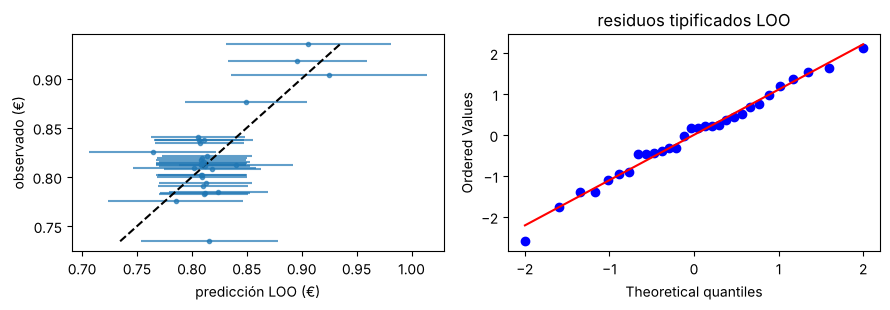

Tiempo total del cuaderno: 87 s


In [49]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].errorbar(ym + ys*mu_l, yv, xerr=2*ys*np.sqrt(var_l), fmt="o", ms=3, alpha=0.7); l = [yv.min(), yv.max()]
ax[0].plot(l, l, "k--"); ax[0].set_xlabel("predicción LOO (€)"); ax[0].set_ylabel("observado (€)")
stats.probplot(r_std, plot=ax[1]); ax[1].set_title("residuos tipificados LOO"); plt.tight_layout(); plt.show()
print(f"Tiempo total del cuaderno: {time.time() - T0_CUADERNO:.0f} s")

## Parte 7 · Retos

1. **Ruido heterocedástico.** El ruido binomial del coste crece con $d$. Sustituye `WhiteKernel` por un `alpha` por punto igual a la varianza binomial estimada y compara el regret.
2. **Mejora esperada con ruido.** Cambia $f^*$ por el mínimo de la **media posterior** en los puntos evaluados (como hace el código) y luego por el mínimo **observado**. ¿Cuál se deja engañar por la maldición del ganador?
3. **Multifidelidad en el hormigón.** Usa los ensayos a 7 días como información adelantada: ajusta un PG a $f_7$ y otro al cociente $f_{28}/f_7$, y decide la semana siguiente sin esperar a los 28 días.
4. **Paso a BoTorch/Ax.** Si tienes `botorch`, reescribe la Parte 4 con `qLogNoisyExpectedImprovement` y restricciones de resultado; compara con esta implementación.
5. **Parada económica.** Detén el bucle cuando el máximo de la EI restringida, multiplicado por la producción anual, sea menor que el coste de un ensayo (300 €). ¿En qué iteración se para?

---
### Soluciones de referencia
Inténtalo antes de mirar.

In [50]:
# --- Ejercicio 1 ---
# def coste_pieza(t_ciclo, d, c_maq=45.0, c_mat=0.40):
#     return (c_maq * np.asarray(t_ciclo) / 3600 + c_mat) / (1 - np.asarray(d))
# --- Ejercicio 2 ---
# def sesgo_ganador(n, sigma, m, rng):
#     return sigma * rng.standard_normal((m, n)).max(axis=1).mean()
# --- Ejercicio 3 ---
# def factorial_2k(k):
#     return np.array(list(itertools.product([-1, 1], repeat=k)))[:, ::-1].astype(float)
# --- Ejercicio 4 ---
# def tabla_efectos(M, Y):
#     Y = np.atleast_2d(Y); N, n = Y.shape
#     ef = M.T @ Y.mean(axis=1) / (N / 2)
#     return ef, n * N * ef**2 / 4
# --- Ejercicio 5 ---
# def es_hipercubo_latino(U):
#     n = U.shape[0]
#     return all(np.array_equal(np.sort(np.floor(U[:, j] * n)), np.arange(n)) for j in range(U.shape[1]))
# --- Ejercicio 6 ---
# def punto_estacionario(b, B):
#     return -0.5 * np.linalg.solve(B, b)
# --- Ejercicio 7 ---
# def gp_posterior(Xtr, ytr, Xte, ell, sf, sn):
#     K = k_se(Xtr, Xtr, ell, sf) + (sn**2 + 1e-10) * np.eye(len(Xtr))
#     L = np.linalg.cholesky(K)
#     alfa = np.linalg.solve(L.T, np.linalg.solve(L, ytr))
#     Ks = k_se(Xtr, Xte, ell, sf)
#     v = np.linalg.solve(L, Ks)
#     return Ks.T @ alfa, np.maximum(sf**2 - (v**2).sum(0), 0)
# --- Ejercicio 8 ---
# def log_verosimilitud_marginal(Xtr, ytr, ell, sf, sn):
#     n = len(ytr)
#     L = np.linalg.cholesky(k_se(Xtr, Xtr, ell, sf) + (sn**2 + 1e-10) * np.eye(n))
#     alfa = np.linalg.solve(L.T, np.linalg.solve(L, ytr))
#     return -0.5 * ytr @ alfa - np.log(np.diag(L)).sum() - 0.5 * n * np.log(2 * np.pi)
# --- Ejercicio 9 ---
# def mezcla_ensemble(mus, sigmas):
#     mus, sigmas = np.asarray(mus), np.asarray(sigmas)
#     mu = mus.mean(0)
#     return mu, np.sqrt((sigmas**2 + mus**2).mean(0) - mu**2)
# --- Ejercicio 10 ---
# def mejora_esperada(mu, sigma, f_mejor):
#     mu, sigma = np.asarray(mu, float), np.asarray(sigma, float)
#     s = np.maximum(sigma, 1e-12); z = (f_mejor - mu) / s
#     ei = (f_mejor - mu) * norm.cdf(z) + s * norm.pdf(z)
#     return np.where(sigma > 1e-12, ei, np.maximum(f_mejor - mu, 0))
# --- Ejercicio 11 ---
# def ei_restringida(mu_f, s_f, f_mejor, mu_c, s_c, limite):
#     return mejora_esperada(mu_f, s_f, f_mejor) * norm.cdf((limite - np.asarray(mu_c)) / np.maximum(s_c, 1e-12))
# --- Ejercicio 12 ---
# def no_dominados(F):
#     F = np.asarray(F)
#     return np.array([not np.any(np.all(F <= f, 1) & np.any(F < f, 1)) for f in F])
# --- Ejercicio 13 ---
# def hipervolumen_2d(F, ref):
#     F = np.asarray(F); F = F[no_dominados(F) & np.all(F < ref, 1)]
#     F = F[np.argsort(F[:, 0])]; hv, y_prev = 0.0, ref[1]
#     for f1, f2 in F:
#         hv += (ref[0] - f1) * (y_prev - f2); y_prev = f2
#     return hv
# --- Ejercicio 14 ---
# def ensayos_busqueda_aleatoria(q, p):
#     return int(math.ceil(math.log(1 - p) / math.log(1 - q)))
# --- Ejercicio 15 ---
# def brackets_hyperband(R, eta):
#     s_max = int(math.floor(math.log(R) / math.log(eta) + 1e-9)); B = (s_max + 1) * R
#     out = []
#     for s in range(s_max, -1, -1):
#         n = int(math.ceil(B / R * eta**s / (s + 1))); r = R * eta**(-s)
#         out.append([(int(math.floor(n * eta**(-i))), r * eta**i) for i in range(s + 1)])
#     return out
# --- Ejercicio 16 ---
# def loo_gp(K, y):
#     Ki = np.linalg.inv(K); d = np.diag(Ki)
#     return y - (Ki @ y) / d, 1 / d